# Paper 25: Sector floors (Halal real economy)

Paper 20 asked whether **capping IT** steadies the path. This paper asks the other construction: **whether insisting on the allowed real economy** — health care, industrials, staples, maybe materials — steadies Calmar / max drawdown without chopping the FCF winners.

v2 last session: **IT ~66%**, communication 9%, health 8%, industrials 6%, staples 2%. Effective names have fallen toward ~18. The 10% name cap stays. The FCF list stays. Weight is pulled from names **already on that list**, not from banned sectors and not by adding weak converters the brain dropped.

Change only `construction.sector_floors`. Brain, overlay, execution, and screens stay on v2. Scored against **v2 baseline**. Kill rules are frozen in `Research/book-construction-status.md`:

- Train 2022 calendar more than 5pp worse than SPUS
- Train max drawdown worse than SPUS
- Train Calmar below both v2 baseline and SPUS
- Test 2023 calendar more than 15pp worse than v2 baseline

**Variants.** `floors-hc-10` (health 10% only), `floors-real-10-10-5` (health 10% / industrials 10% / staples 5% — the write-up's main try), `floors-plus-materials` (same plus materials 5%). Kill a floor if it forces a thin FCF tail and 2023 dies, or if max drawdown / Calmar does not actually move versus v2.


In [1]:
import subprocess
import sys
from pathlib import Path

def _repo_root() -> Path:
    start = Path.cwd().resolve()
    for candidate in (start, *start.parents):
        if (candidate / "monterey" / "__init__.py").exists():
            return candidate
    raise FileNotFoundError(f"Monterey repo root not found from {start}")

_ROOT = _repo_root()
if str(_ROOT) not in sys.path:
    sys.path.insert(0, str(_ROOT))
try:
    import monterey  # noqa: F401
except ModuleNotFoundError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-e", f"{_ROOT}[research]"])

from monterey.research import boot, compare, run_book
from monterey.sprints import score_against_baseline
from monterey.spec import BookSpec

rd = boot("paper-25-sector-floors", start="2019-12-01", end="2026-09-30")
print("snapshot", rd.manifest.get("hash"))
print("v2 hash", BookSpec.load("fcf-sma-v2-baseline").hash())
print("sector labels", sorted(set(rd.sectors.values())))

base = run_book(
    "fcf-sma-v2-baseline",
    rd,
    paper="25-sector-floors",
    id="v2",
)


[monterey.data] Loading snapshot ebbbefb35545
        field                   value
       window 2019-12-01 → 2026-09-30
     universe    sp500, point-in-time
      symbols                     631
    snapshots                      85
   price rows                 1147266
    dividends                    9754
filing events                   61274
   halalquant                   0.4.0
snapshot hash            ebbbefb35545
snapshot ebbbefb35545
v2 hash 6ca86844209e
sector labels ['alcohol', 'basic materials', 'communication services', 'consumer cyclical', 'consumer defensive', 'consumer discretionary', 'consumer staples', 'conventional banking', 'conventional insurance', 'defense', 'energy', 'financial services', 'financials', 'gambling', 'health care', 'healthcare', 'industrials', 'information technology', 'materials', 'real estate', 'technology', 'tobacco', 'utilities']


## One budget at a time

Each trial copies v2 and sets only `construction.sector_floors`. The 10% name cap is unchanged. There is no `sector_cap` — that is paper 20. Labels match GICS names case-insensitively; a floor whose sector has no FCF names that month is skipped.


In [2]:
HC10 = {"Health Care": 0.10}
REAL = {"Health Care": 0.10, "Industrials": 0.10, "Consumer Staples": 0.05}
PLUS = {**REAL, "Materials": 0.05}

hc10 = run_book(
    "fcf-sma-v2-baseline",
    rd,
    paper="25-sector-floors",
    id="floors-hc-10",
    construction={"sector_floors": HC10},
)
real = run_book(
    "fcf-sma-v2-baseline",
    rd,
    paper="25-sector-floors",
    id="floors-real-10-10-5",
    construction={"sector_floors": REAL},
)
plus = run_book(
    "fcf-sma-v2-baseline",
    rd,
    paper="25-sector-floors",
    id="floors-plus-materials",
    construction={"sector_floors": PLUS},
)

trials = [hc10, real, plus]
for book in [base, *trials]:
    print(book.spec.id, book.spec.hash())
    print(" ", dict(book.spec.summary()))
    if book is not base:
        assert book.spec.hash() != base.spec.hash()


v2 6ca86844209e
  {'book': 'v2', 'hash': '6ca86844209e', 'universe': 'sp500 point-in-time', 'sector screen': 'on', 'AAOIFI lines': 'debt 30% / cash 30% / recv 70%', 'breach exit': 'next_open', 'brain': 'fcf_quality (keep_quantile=0.5, min_holdings=20)', 'weights': 'cap', 'name cap': '10%', 'sector cap': 'none', 'sector floors': 'none', 'throttle': 'SPY 200-day SMA', 'rebalance': 'daily_to_target, drift band 0.0%, min $100', 'dividends': 'credited', 'cost': '10 bp charged', 'purify': 'ex_date'}
floors-hc-10 0c82f2324a51
  {'book': 'floors-hc-10', 'hash': '0c82f2324a51', 'universe': 'sp500 point-in-time', 'sector screen': 'on', 'AAOIFI lines': 'debt 30% / cash 30% / recv 70%', 'breach exit': 'next_open', 'brain': 'fcf_quality (keep_quantile=0.5, min_holdings=20)', 'weights': 'cap', 'name cap': '10%', 'sector cap': 'none', 'sector floors': 'Health Care 10%', 'throttle': 'SPY 200-day SMA', 'rebalance': 'daily_to_target, drift band 0.0%, min $100', 'dividends': 'credited', 'cost': '10 bp ch

In [3]:
compare([base, *trials], rd)


,total_return,cagr,volatility,max_drawdown,calmar,sharpe,sortino,turnover,costs_pct,dividends_pct,avg_exposure,switches,hash
book,,,,,,,,,,,,,
v2,1.0644,0.1137,0.1463,-0.2482,0.4582,0.6752,0.8589,4.1653,0.0561,0.0561,0.8032,36.0000,6ca86844209e
floors-hc-10,1.0583,0.1132,0.1445,-0.2483,0.4561,0.6786,0.8640,4.1888,0.0564,0.0565,0.8032,36.0000,0c82f2324a51
floors-real-10-10-5,0.9956,0.1081,0.1396,-0.2469,0.4379,0.6646,0.8458,4.2234,0.0568,0.0594,0.8032,36.0000,15d24a18cfd1
floors-plus-materials,0.9895,0.1076,0.1371,-0.2449,0.4395,0.6708,0.8542,4.2700,0.0575,0.0648,0.8032,36.0000,0740c59235cb
SPUS (total return),2.1167,0.1840,0.2116,-0.3080,0.5975,0.8123,1.0828,NaN,NaN,NaN,NaN,NaN,NaN
SPY (total return),1.6113,0.1533,0.2006,-0.3372,0.4547,0.7140,0.8854,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
for trial in trials:
    verdict = score_against_baseline(trial, base, rd)
    reasons = "; ".join(verdict["reasons"]) or "pass"
    print(trial.spec.id, "KILLED" if verdict["killed"] else "keep", reasons)


floors-hc-10 KILLED train Calmar below both v2 baseline and SPUS
floors-real-10-10-5 keep pass
floors-plus-materials keep pass


## Did the floors bind?

`compare` only sees NAV. Before we trust a Calmar move, check that health / industrials / staples actually rose on a few month-ends, that IT fell because weight was reallocated **inside** the FCF list, and that no new names appeared just to fill a starved sector.


In [5]:
import pandas as pd
from monterey.layers import build_weights, screen
from monterey.layers.signals import Context, run_brain

DAYS = ["2020-03-31", "2022-06-30", "2023-12-29", "2024-12-31"]
WATCH = ("health care", "industrials", "consumer staples", "materials", "information technology")

SPECS = {
    "v2": BookSpec.load("fcf-sma-v2-baseline"),
    "floors-hc-10": BookSpec.load("fcf-sma-v2-baseline").replace(id="floors-hc-10", construction={"sector_floors": HC10}),
    "floors-real-10-10-5": BookSpec.load("fcf-sma-v2-baseline").replace(id="floors-real-10-10-5", construction={"sector_floors": REAL}),
    "floors-plus-materials": BookSpec.load("fcf-sma-v2-baseline").replace(id="floors-plus-materials", construction={"sector_floors": PLUS}),
}


def mix(spec, day: str):
    held = screen(rd, day, spec)
    picked = run_brain(Context(data=rd, spec=spec, as_of=pd.Timestamp(day).date(), screen=held))
    weights = build_weights(picked, spec, rd.sectors)
    names = set(weights.index.astype(str))
    def _key(symbol):
        label = (rd.sectors.get(symbol) or "unknown").strip().lower()
        return "health care" if label == "healthcare" else label

    by_sector = weights.groupby(weights.index.map(_key)).sum()
    return names, by_sector


rows = []
for day in DAYS:
    base_names, _ = mix(SPECS["v2"], day)
    for name, spec in SPECS.items():
        names, by_sector = mix(spec, day)
        row = {
            "day": day,
            "book": name,
            "n": len(names),
            "added_vs_v2": len(names - base_names),
            "dropped_vs_v2": len(base_names - names),
        }
        for sector in WATCH:
            row[sector] = float(by_sector.get(sector, 0.0))
        rows.append(row)

census = pd.DataFrame(rows)
census


,day,book,n,added_vs_v2,dropped_vs_v2,health care,industrials,consumer staples,materials,information technology
0,2020-03-31,v2,82,0,0,0.1885,0.0609,0.0759,0.0237,0.2982
1,2020-03-31,floors-hc-10,82,0,0,0.1885,0.0609,0.0759,0.0237,0.2982
2,2020-03-31,floors-real-10-10-5,82,0,0,0.1841,0.1000,0.0746,0.0225,0.2834
3,2020-03-31,floors-plus-materials,82,0,0,0.1809,0.1000,0.0737,0.0500,0.2727
4,2022-06-30,v2,98,0,0,0.2687,0.0745,0.0543,0.0317,0.3612
5,2022-06-30,floors-hc-10,98,0,0,0.2687,0.0745,0.0543,0.0317,0.3612
6,2022-06-30,floors-real-10-10-5,98,0,0,0.2631,0.1000,0.0541,0.0306,0.3493
7,2022-06-30,floors-plus-materials,98,0,0,0.2587,0.1000,0.0540,0.0500,0.3399
8,2023-12-29,v2,94,0,0,0.1544,0.0583,0.0494,0.0112,0.3910
9,2023-12-29,floors-hc-10,94,0,0,0.1544,0.0583,0.0494,0.0112,0.3910


## Path, not just the scorecard

Plot growth of $1 and drawdown. Then the quantity the rule claims to change: invested weight in the starved Halal sectors versus IT.


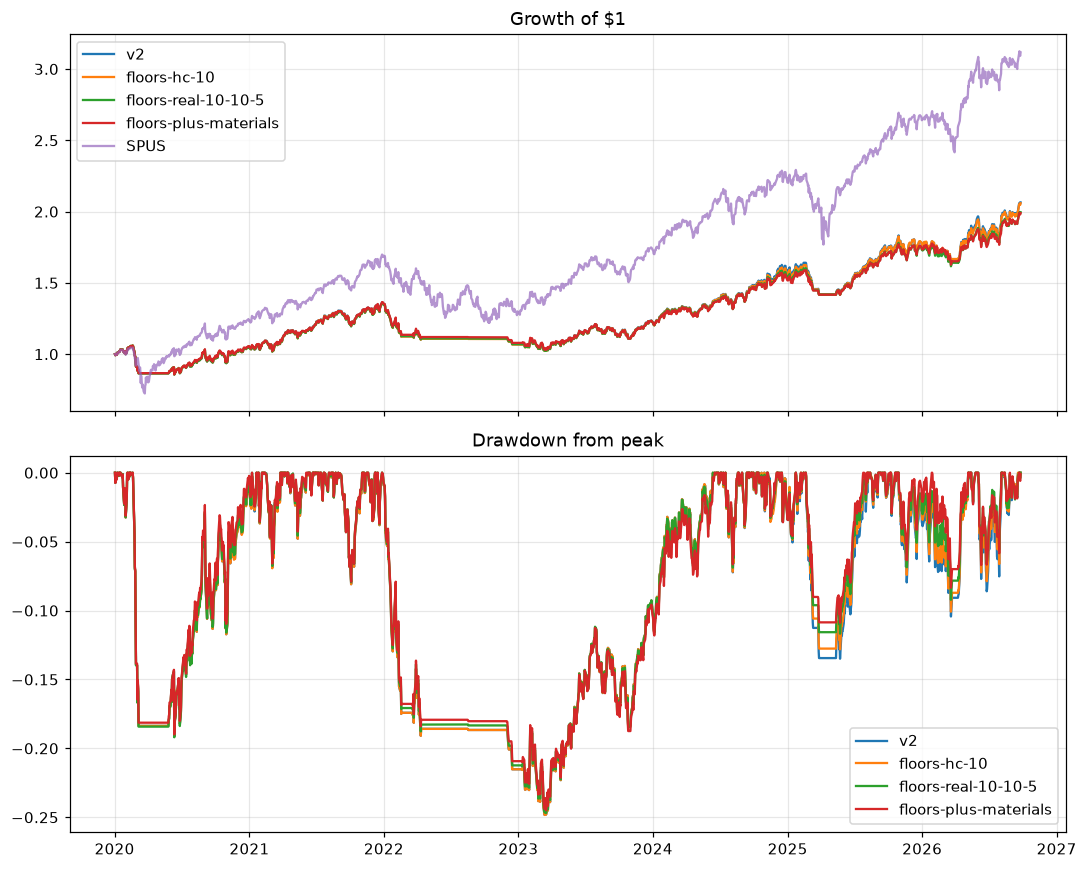

wrote figures/nav-and-drawdown.png


In [6]:
import matplotlib.pyplot as plt
from monterey.diagnostics import yearly

books = [base, *trials]
figures = Path("figures")
figures.mkdir(exist_ok=True)

spus = rd.total_return("SPUS").reindex(base.nav_series().index).ffill()

fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
for book in books:
    nav = book.nav_series()
    axes[0].plot(nav.index, nav / nav.iloc[0], label=book.spec.id)
    dd = nav / nav.cummax() - 1.0
    axes[1].plot(dd.index, dd, label=book.spec.id)
axes[0].plot(spus.index, spus / spus.iloc[0], label="SPUS", alpha=0.7)
axes[0].set_title("Growth of $1")
axes[0].legend()
axes[1].set_title("Drawdown from peak")
axes[1].legend()
fig.tight_layout()
fig.savefig(figures / "nav-and-drawdown.png", dpi=140)
plt.show()
print("wrote", figures / "nav-and-drawdown.png")


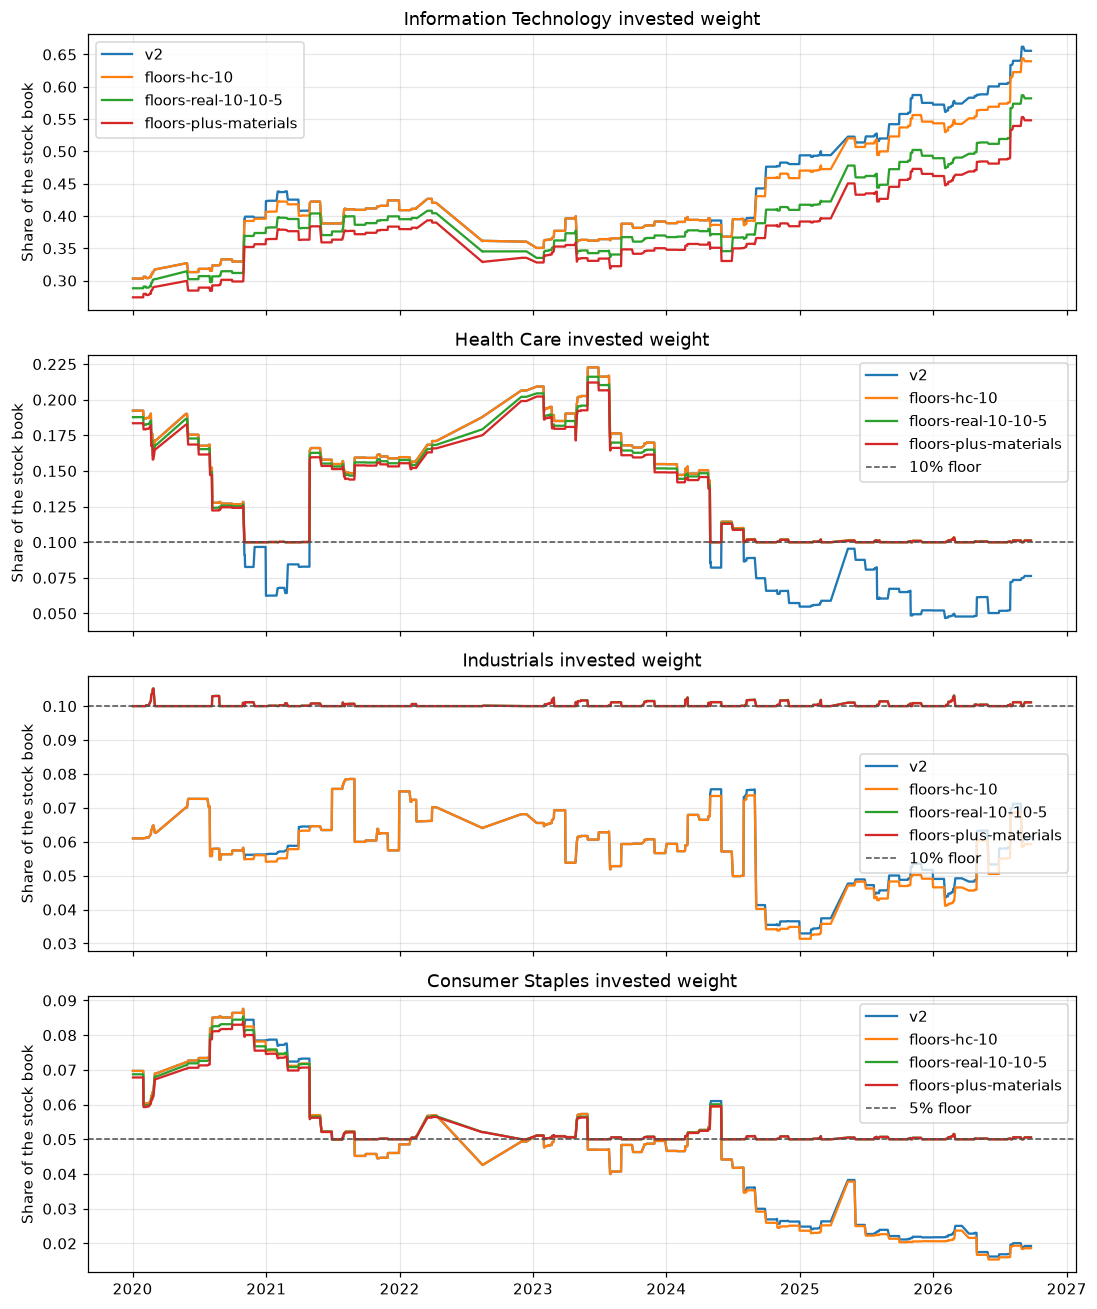

wrote figures/sector-floors.png


In [7]:
def invested_sector_weight(ledger, needle: str) -> pd.Series:
    pos = ledger.positions.copy()
    pos["date"] = pd.to_datetime(pos["date"])
    pos["invested_weight"] = pos["invested_weight"].astype(float)
    live = pos[pos["invested_weight"] > 0]
    if live.empty:
        return pd.Series(dtype=float)
    tot = live.groupby("date")["invested_weight"].sum()
    labels = live["sector"].fillna("").str.lower().replace({"healthcare": "health care"})
    hit = live[labels == needle]
    return hit.groupby("date")["invested_weight"].sum().reindex(tot.index).fillna(0.0) / tot

fig, axes = plt.subplots(4, 1, figsize=(10, 12), sharex=True)
tracks = [
    ("information technology", "Information Technology", None),
    ("health care", "Health Care", 0.10),
    ("industrials", "Industrials", 0.10),
    ("consumer staples", "Consumer Staples", 0.05),
]
for ax, (needle, title, floor) in zip(axes, tracks):
    for book in books:
        series = invested_sector_weight(book, needle)
        ax.plot(series.index, series, label=book.spec.id)
    if floor is not None:
        ax.axhline(floor, color="0.3", ls="--", lw=1, label=f"{floor:.0%} floor")
    ax.set_title(f"{title} invested weight")
    ax.set_ylabel("Share of the stock book")
    ax.legend()
fig.tight_layout()
fig.savefig(figures / "sector-floors.png", dpi=140)
plt.show()
print("wrote", figures / "sector-floors.png")


,v2,floors-hc-10,floors-real-10-10-5,floors-plus-materials,SPUS
year,,,,,
2020,0.0528,0.0520,0.0519,0.0564,0.2399
2021,0.2831,0.2818,0.2817,0.2827,0.3562
2022,-0.2080,-0.2081,-0.2061,-0.2036,-0.2276
2023,0.1525,0.1525,0.1488,0.1401,0.3420
2024,0.2741,0.2633,0.2460,0.2337,0.2649
2025,0.1250,0.1380,0.1303,0.1446,0.1978
2026,0.1681,0.1633,0.1524,0.1452,0.1802


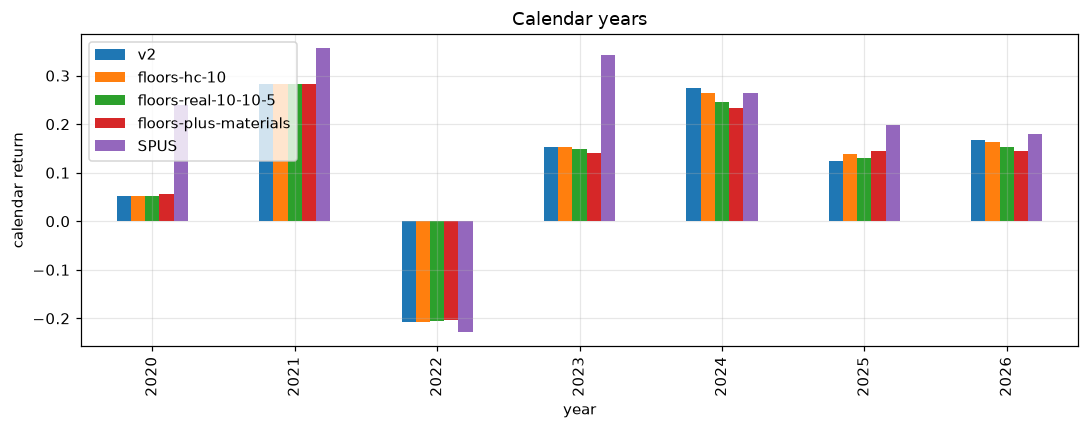

wrote figures/calendar-returns.png


In [8]:
calendar = pd.concat({book.spec.id: yearly(book.nav_series())["return"] for book in books}, axis=1)
calendar["SPUS"] = yearly(spus)["return"]
display(calendar)

ax = calendar.plot(kind="bar", figsize=(10, 4))
ax.set_ylabel("calendar return")
ax.set_title("Calendar years")
fig = ax.get_figure()
fig.tight_layout()
fig.savefig(figures / "calendar-returns.png", dpi=140)
plt.show()
print("wrote", figures / "calendar-returns.png")


## Last-session mix and 2023

A board that cares about riba-free real activity should not be 2% staples by accident. The last session mix is the honesty check. 2023 is the kill check: if the floors starve the mega-cap path that year, this is not a live rule.


In [9]:
from monterey.diagnostics import diagnose, yearly

rows = []
for book in books:
    diag = diagnose(book, rd)
    perf = diag["performance"]
    cal = yearly(book.nav_series())["return"]
    mix = diag.get("sectors") or {}
    row = {
        "book": book.spec.id,
        "calmar": perf.get("calmar"),
        "max_drawdown": perf.get("max_drawdown"),
        "ret_2023": float(cal.loc[2023]) if 2023 in cal.index else None,
        **{str(sector): float(weight) for sector, weight in mix.items()},
    }
    rows.append(row)
    print(book.spec.id, "last-session mix")
    for sector, weight in sorted(mix.items(), key=lambda kv: -kv[1]):
        print(f"  {sector:30s} {weight:6.1%}")

pd.DataFrame(rows)


v2 last-session mix
  information technology          65.6%
  communication services           9.4%
  health care                      7.6%
  industrials                      6.1%
  financials                       5.0%
  consumer discretionary           3.3%
  consumer staples                 1.9%
  materials                        0.8%
  energy                           0.3%
floors-hc-10 last-session mix
  information technology          64.0%
  health care                     10.1%
  communication services           9.1%
  industrials                      5.9%
  financials                       4.8%
  consumer discretionary           3.2%
  consumer staples                 1.9%
  materials                        0.8%
  energy                           0.2%
floors-real-10-10-5 last-session mix
  information technology          58.2%
  industrials                     10.1%
  health care                     10.1%
  communication services           8.3%
  consumer staples               

,book,calmar,max_drawdown,ret_2023,information technology,communication services,health care,industrials,financials,consumer discretionary,consumer staples,materials,energy
0,v2,0.4582,-0.2482,0.1525,0.6557,0.0942,0.0763,0.0613,0.0496,0.0329,0.0193,0.0082,0.0026
1,floors-hc-10,0.4561,-0.2483,0.1525,0.6395,0.0911,0.1013,0.0593,0.0480,0.0318,0.0186,0.0079,0.0025
2,floors-real-10-10-5,0.4379,-0.2469,0.1488,0.5821,0.0829,0.1012,0.1012,0.0437,0.0290,0.0506,0.0072,0.0022
3,floors-plus-materials,0.4395,-0.2449,0.1401,0.5481,0.0781,0.1011,0.1011,0.0411,0.0273,0.0505,0.0505,0.0021
